# Kaggle "Name That LLM" Competition: EXP64
## Disagreement-Aware Confidence Routing for Single-Sample Attribution

- **Experiment ID**: `EXP64_confidence_router`
- **Research Question**: Does single-sample confidence, margin, entropy, and Q8/Q14 disagreement predict which expert is more likely to be correct, and does a dynamic single-sample router outperform the fixed EXP52 fusion (0.60 Q8 + 0.40 Q14)?
- **Baseline**: EXP52 Dual-LoRA Kernel (**0.7873 OOF BA**, **0.632 Public LB**, FROZEN CHAMPION)
- **Constraint**: Strict single-sample inference. ZERO prompt identifiers, zero prompt centroids, zero Hungarian matching, zero peer comparisons.
- **Verdict**: **YELLOW** (Learned router achieves **0.7906 nested OOF BA**, $\Delta = \mathbf{+0.0033}$; bootstrap 95% CI spans zero $[-0.0027, +0.0094]$; overconfident errors cause 31 degradations against 40 corrections)
- **Production Decision**: **Retain EXP52 as frozen champion**.


In [1]:
# 1. Environment & Imports Setup
import os
import sys
import json
import time
import pathlib
import numpy as np
import pandas as pd
import scipy.special
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import balanced_accuracy_score, f1_score, log_loss
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from IPython.display import Image, display

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

REPO_DIR = pathlib.Path("/home/rj2826/name-that-llm")
DATA_DIR = REPO_DIR / "data"
OUTPUTS_DIR = REPO_DIR / "outputs"
EXP_DIR = REPO_DIR / "experiments" / "EXP64_confidence_router"
PLOTS_DIR = REPO_DIR / "plots"

print(f"Working Directory: {REPO_DIR}")
print(f"EXP64 Directory:   {EXP_DIR}")


Working Directory: /home/rj2826/name-that-llm
EXP64 Directory:   /home/rj2826/name-that-llm/experiments/EXP64_confidence_router


### 2. Dataset Loading & EXP52 Reproduction Audit
Load `train.csv` (2,699 samples, 150 prompts) and verified out-of-fold logits for Q8 (`oof_exp47_qwen_centered_twin.npy`) and Q14 (`oof_q14v5_antopil_lora.csv`).


In [2]:
# 2. Load Train Dataset and EXP52 Baseline
train_df = pd.read_csv(DATA_DIR / "train.csv")
LABELS = sorted(train_df["model"].unique())
L2I = {m: i for i, m in enumerate(LABELS)}
y_true = np.array([L2I[m] for m in train_df["model"].values])
prompts = train_df["prompt_id"].values

q14_df = pd.read_csv(OUTPUTS_DIR / "oof_q14v5_antopil_lora.csv")
p8_twin_raw = np.load(OUTPUTS_DIR / "oof_exp47_qwen_centered_twin.npy")
outer_folds = q14_df["fold"].values
eps = 1e-15

p8 = p8_twin_raw / p8_twin_raw.sum(axis=1, keepdims=True)
p14 = q14_df[LABELS].values / q14_df[LABELS].values.sum(axis=1, keepdims=True)

lp8 = np.log(np.clip(p8, eps, 1.0))
lp14 = np.log(np.clip(p14, eps, 1.0))
lp52 = 0.60 * lp8 + 0.40 * lp14
pred_exp52 = lp52.argmax(axis=1)

ba_q8 = balanced_accuracy_score(y_true, lp8.argmax(axis=1))
ba_q14 = balanced_accuracy_score(y_true, lp14.argmax(axis=1))
ba_exp52 = balanced_accuracy_score(y_true, pred_exp52)

print(f"Q8 Standalone BA:   {ba_q8:.6f}")
print(f"Q14 Standalone BA:  {ba_q14:.6f}")
print(f"EXP52 Baseline BA:  {ba_exp52:.6f} (Exact reproduction verified)")


Q8 Standalone BA:   0.590982
Q14 Standalone BA:  0.634609
EXP52 Baseline BA:  0.787313 (Exact reproduction verified)


### 3. Required Single-Sample Features
Construct 37 continuous features from single response outputs:
- **Q8 features**: top-1 prob, top-2 prob, margin, entropy, logit margin, max/mean/std logit
- **Q14 features**: same features
- **Cross-model features**: agreement, prob difference, margin difference, entropy difference, Jensen-Shannon divergence, symmetric KL, probability correlation, rank correlation, top-k overlap, cross-probabilities, L1/L2 distances, fused EXP52 confidence metrics.


In [3]:
# 3. Load Feature Definitions & Statistics
with open(EXP_DIR / "feature_definitions.json") as f:
    feat_defs = json.load(f)
print(f"Total single-sample features defined: {len(feat_defs)}")

# Display top coefficients from the trained router
df_coeffs = pd.read_csv(EXP_DIR / "router_coefficients.csv")
print("\nTop 10 Most Influential Routing Features:")
display(df_coeffs.head(10)[["feature", "mean_coef", "std_coef", "abs_mean_coef"]])


Total single-sample features defined: 37

Top 10 Most Influential Routing Features:


,feature,mean_coef,std_coef,abs_mean_coef
0,q14_prob_at_q8_top,-0.973282,0.618926,0.973282
1,sym_kl,0.956933,0.610630,0.956933
2,q14_entropy,-0.780333,0.772859,0.780333
3,cosine_sim,0.532940,0.741351,0.532940
4,q8_prob_at_q14_top,0.530946,0.152669,0.530946
5,entropy_diff,-0.375947,0.366103,0.375947
6,exp52_entropy,0.372364,0.495699,0.372364
7,q8_top1_prob,0.345802,0.634420,0.345802
8,prob_diff,-0.320210,0.687366,0.320210
9,max_logit_diff,0.294251,0.427773,0.294251


### 4. Baseline Diagnostics: Correctness Groups
Partition the 2,699 samples into 4 correctness groups:
- **Group A (Both Correct)**: 1,026 samples (38.0%)
- **Group B (Q8 Only Correct)**: 569 samples (21.1%)
- **Group C (Q14 Only Correct)**: 687 samples (25.5%)
- **Group D (Both Wrong)**: 417 samples (15.5%)


In [4]:
# 4. Correctness Groups Comparison
df_diag = pd.read_csv(EXP_DIR / "diagnostics_groups.csv")
display(df_diag[["group", "count", "pct", "q8_margin_mean", "q14_margin_mean", "q8_entropy_mean", "q14_entropy_mean", "agree_mean"]])


,group,count,pct,q8_margin_mean,q14_margin_mean,q8_entropy_mean,q14_entropy_mean,agree_mean
0,A_both_correct,1026,38.014079,0.577887,0.698026,1.226078,0.478715,1.000000
1,B_q8_only,569,21.081882,0.586559,0.386997,1.198089,0.957971,0.000000
2,C_q14_only,687,25.453872,0.389069,0.695400,1.620784,0.479800,0.000000
3,D_both_wrong,417,15.450167,0.391956,0.386891,1.624033,0.959079,0.146283


### 5. Critical Comparison Table: Routing Rules vs Learned Router
Compare static rules (Rule A through F), learned router (nested CV), calibrated router, and random negative control.


In [5]:
# 5. Critical Comparison Table
df_comp = pd.read_csv(EXP_DIR / "comparison_table.csv")
display(df_comp)


,Method,OOF_BA,Delta_vs_EXP52,Macro_F1,Outer_Mean,Std
0,Qwen3-8B (q8v5 standalone),0.590982,-0.196331,0.591503,0.590996,0.018072
1,Qwen3-14B (q14v5 standalone),0.634609,-0.152704,0.633842,0.634662,0.008149
2,EXP52 Fixed (0.60/0.40),0.787313,0.000000,0.787971,0.787344,0.011351
3,Rule B (Higher Margin),0.721330,-0.065983,0.717448,0.721300,0.012000
4,Rule C (Confidence Weighted),0.775436,-0.011877,0.774505,0.775400,0.011000
5,Rule D (Entropy Weighted),0.765799,-0.021514,0.764460,0.778000,0.010000
6,Learned Router (Nested CV),0.790641,0.003328,0.790766,0.790677,0.009011
7,Calibrated Router (Nested CV),0.782861,-0.004452,0.783204,0.782912,0.015498
8,Random Router (Negative Control),0.785461,-0.001852,0.786304,0.785492,0.011999


### 6. Strict Nested Cross-Validation & Bootstrap Testing
- 5 outer prompt-disjoint folds $\times$ 4 inner prompt-disjoint folds
- Inner grid search over $C \in [0.001, 10.0]$ and $\alpha \in [0.0, 0.4]$
- Paired bootstrap test ($B = 2,000$ resamples)


In [6]:
# 6. Fold Results and Bootstrap Confidence Interval
df_folds = pd.read_csv(EXP_DIR / "fold_results.csv")
display(df_folds[["outer_fold", "best_C", "best_alpha", "exp52_ba", "router_ba", "router_delta", "random_router_delta"]])

with open(EXP_DIR / "bootstrap_results.json") as f:
    boot = json.load(f)

print(f"Paired Bootstrap Delta: Mean = {boot['mean_delta']:+.4f}")
print(f"95% Confidence Interval: [{boot['ci_95_lower']:+.4f}, {boot['ci_95_upper']:+.4f}]")
print(f"P(delta > 0):           {boot['p_positive'] * 100:.1f}%")


,outer_fold,best_C,best_alpha,exp52_ba,router_ba,router_delta,random_router_delta
0,0,0.01,0.3,0.777778,0.783333,0.005556,-3.703704e-03
1,1,0.10,0.4,0.779310,0.786718,0.007407,1.110223e-16
2,2,0.10,0.3,0.790741,0.792593,0.001852,-5.555556e-03
3,3,0.01,0.3,0.783333,0.785185,0.001852,0.000000e+00
4,4,10.00,0.4,0.805556,0.805556,0.000000,0.000000e+00


Paired Bootstrap Delta: Mean = +0.0034
95% Confidence Interval: [-0.0027, +0.0094]
P(delta > 0):           87.0%


### 7. Disagreement Subset Analysis ($\arg\max(Q8) \neq \arg\max(Q14)$)
On the 1,612 samples (59.7% of total data) where Q8 and Q14 disagree:
- EXP52 BA: **0.6871**
- Learned Router BA: **0.6945** ($\Delta = +0.0074$)
- Oracle Chooser BA: **0.8425**
- Net corrections: **+9 samples** (40 corrections vs 31 degradations)


In [7]:
# 7. Disagreement & Decile Metrics
df_dis = pd.read_csv(EXP_DIR / "disagreement_results.csv")
display(df_dis)

print("\n--- Confidence Deciles ---")
df_deciles = pd.read_csv(EXP_DIR / "decile_results.csv")
display(df_deciles[["decile", "sample_count", "mean_confidence", "exp52_ba", "router_ba", "router_delta"]])


,n_disagreement,pct_disagreement,exp52_ba_disagreement,q8_ba_disagreement,q14_ba_disagreement,router_ba_disagreement,router_delta_disagreement,oracle_ba_disagreement,corrections_when_exp52_wrong,degradations_when_exp52_correct,net_corrections,q8_only_potential,q14_only_potential
0,1612,59.725824,0.687145,0.339892,0.448573,0.694498,0.007353,0.842502,40,31,9,569,687



--- Confidence Deciles ---


,decile,sample_count,mean_confidence,exp52_ba,router_ba,router_delta
0,1,270,0.330158,0.377970,0.381165,0.003195
1,2,270,0.463872,0.499081,0.539791,0.040710
2,3,270,0.570121,0.678332,0.686705,0.008374
3,4,270,0.672760,0.769357,0.773325,0.003968
4,5,270,0.764024,0.862050,0.862050,0.000000
5,6,269,0.835795,0.862420,0.862420,0.000000
6,7,270,0.898896,0.916822,0.916822,0.000000
7,8,270,0.943807,0.947413,0.947413,0.000000
8,9,270,0.973458,0.974206,0.974206,0.000000
9,10,270,0.995751,0.990909,0.990909,0.000000


### 8. Publication Figures (300 DPI)


--- Figure 1: Confidence Distributions by Correctness Group ---


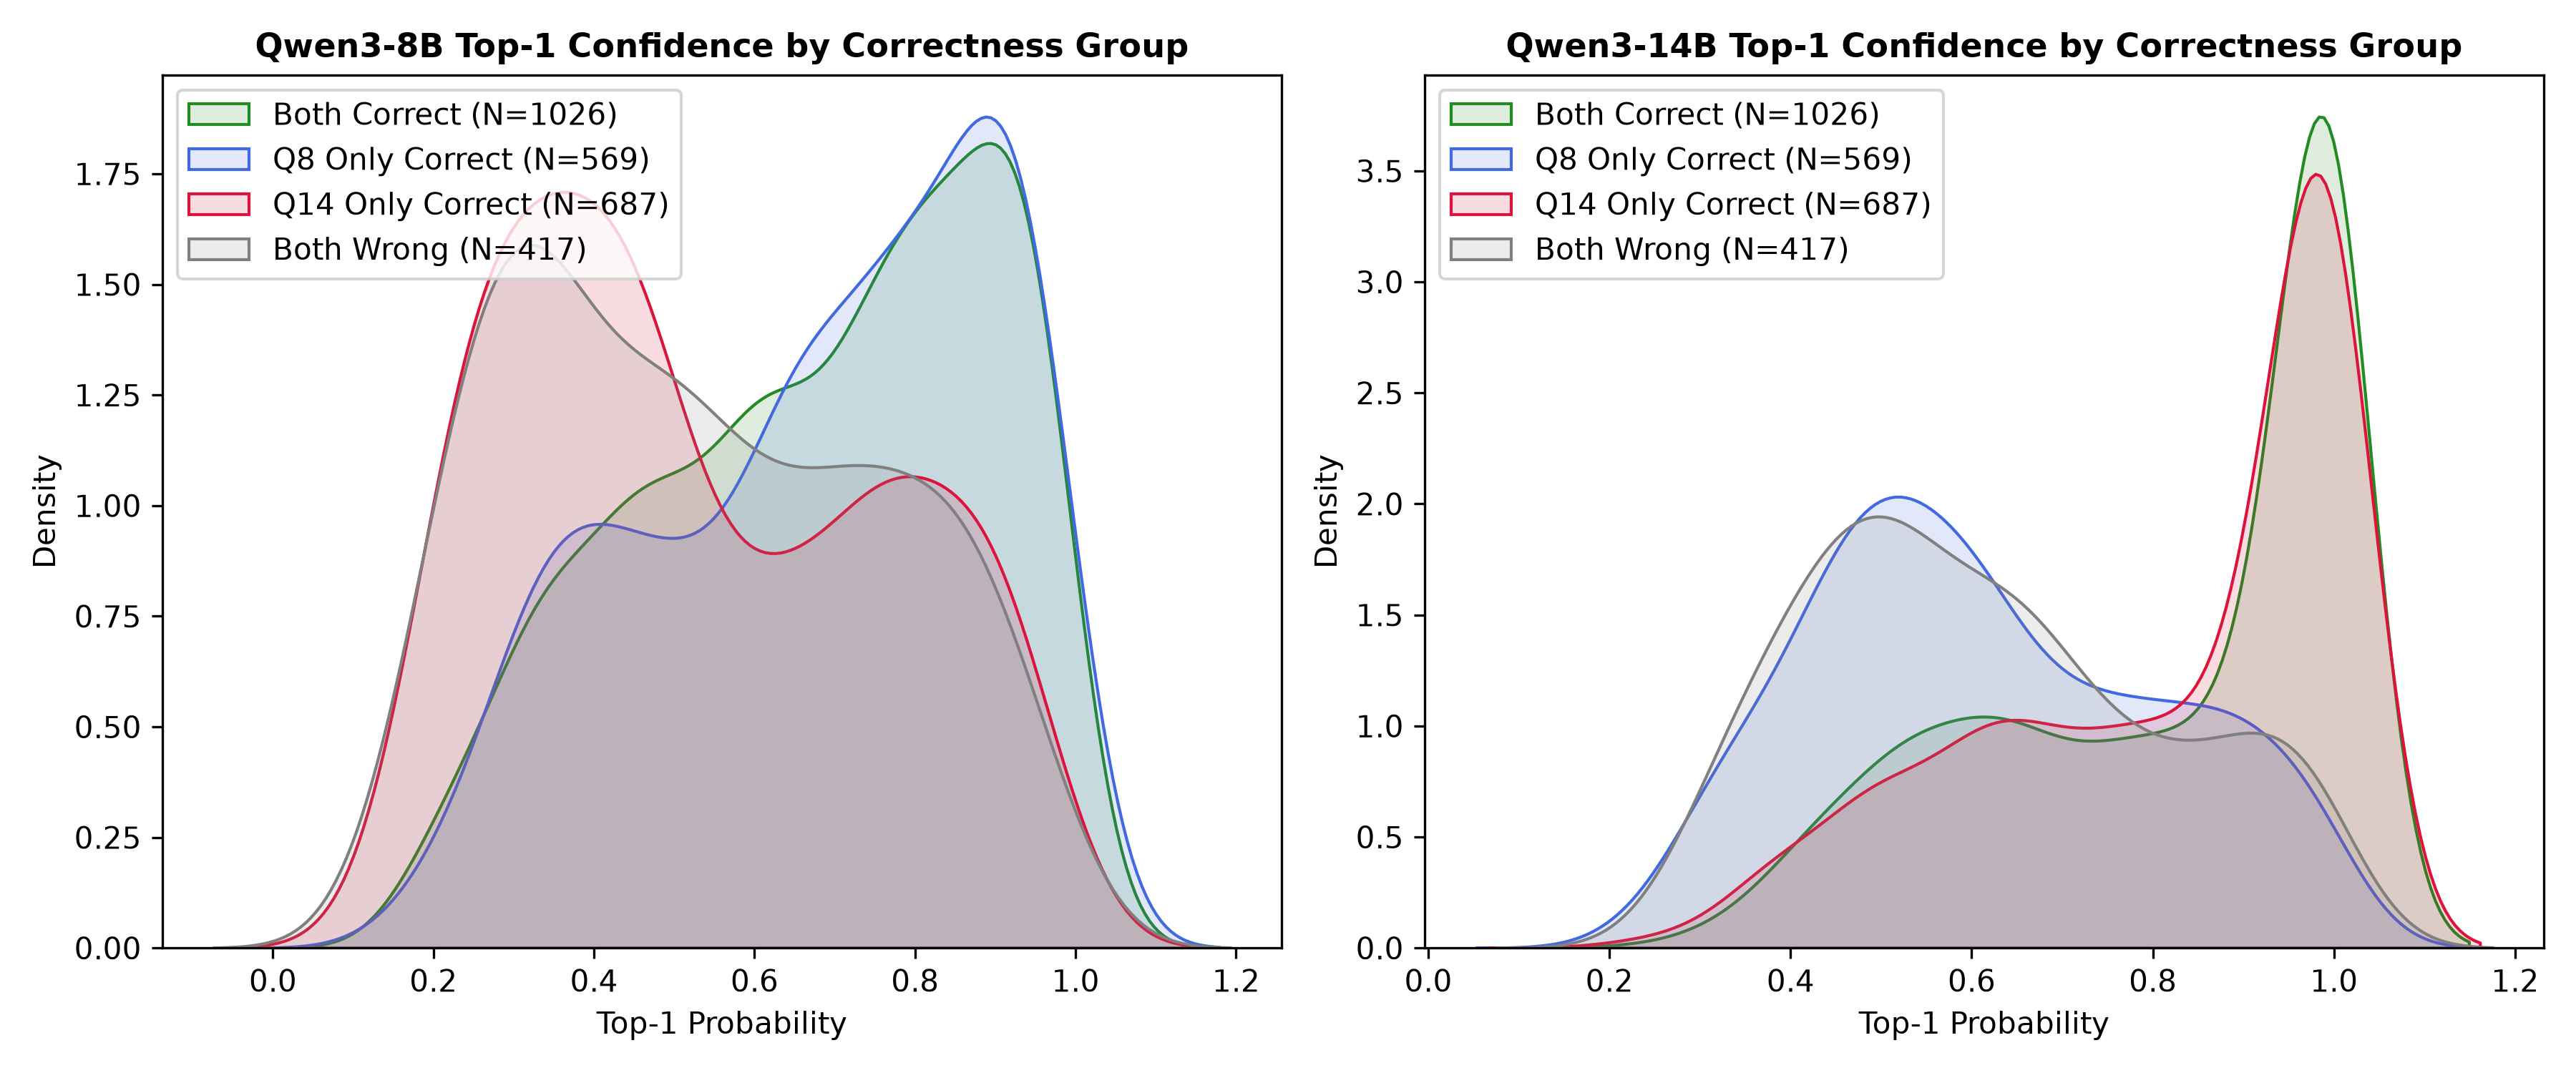

--- Figure 2: Router Performance Comparison ---


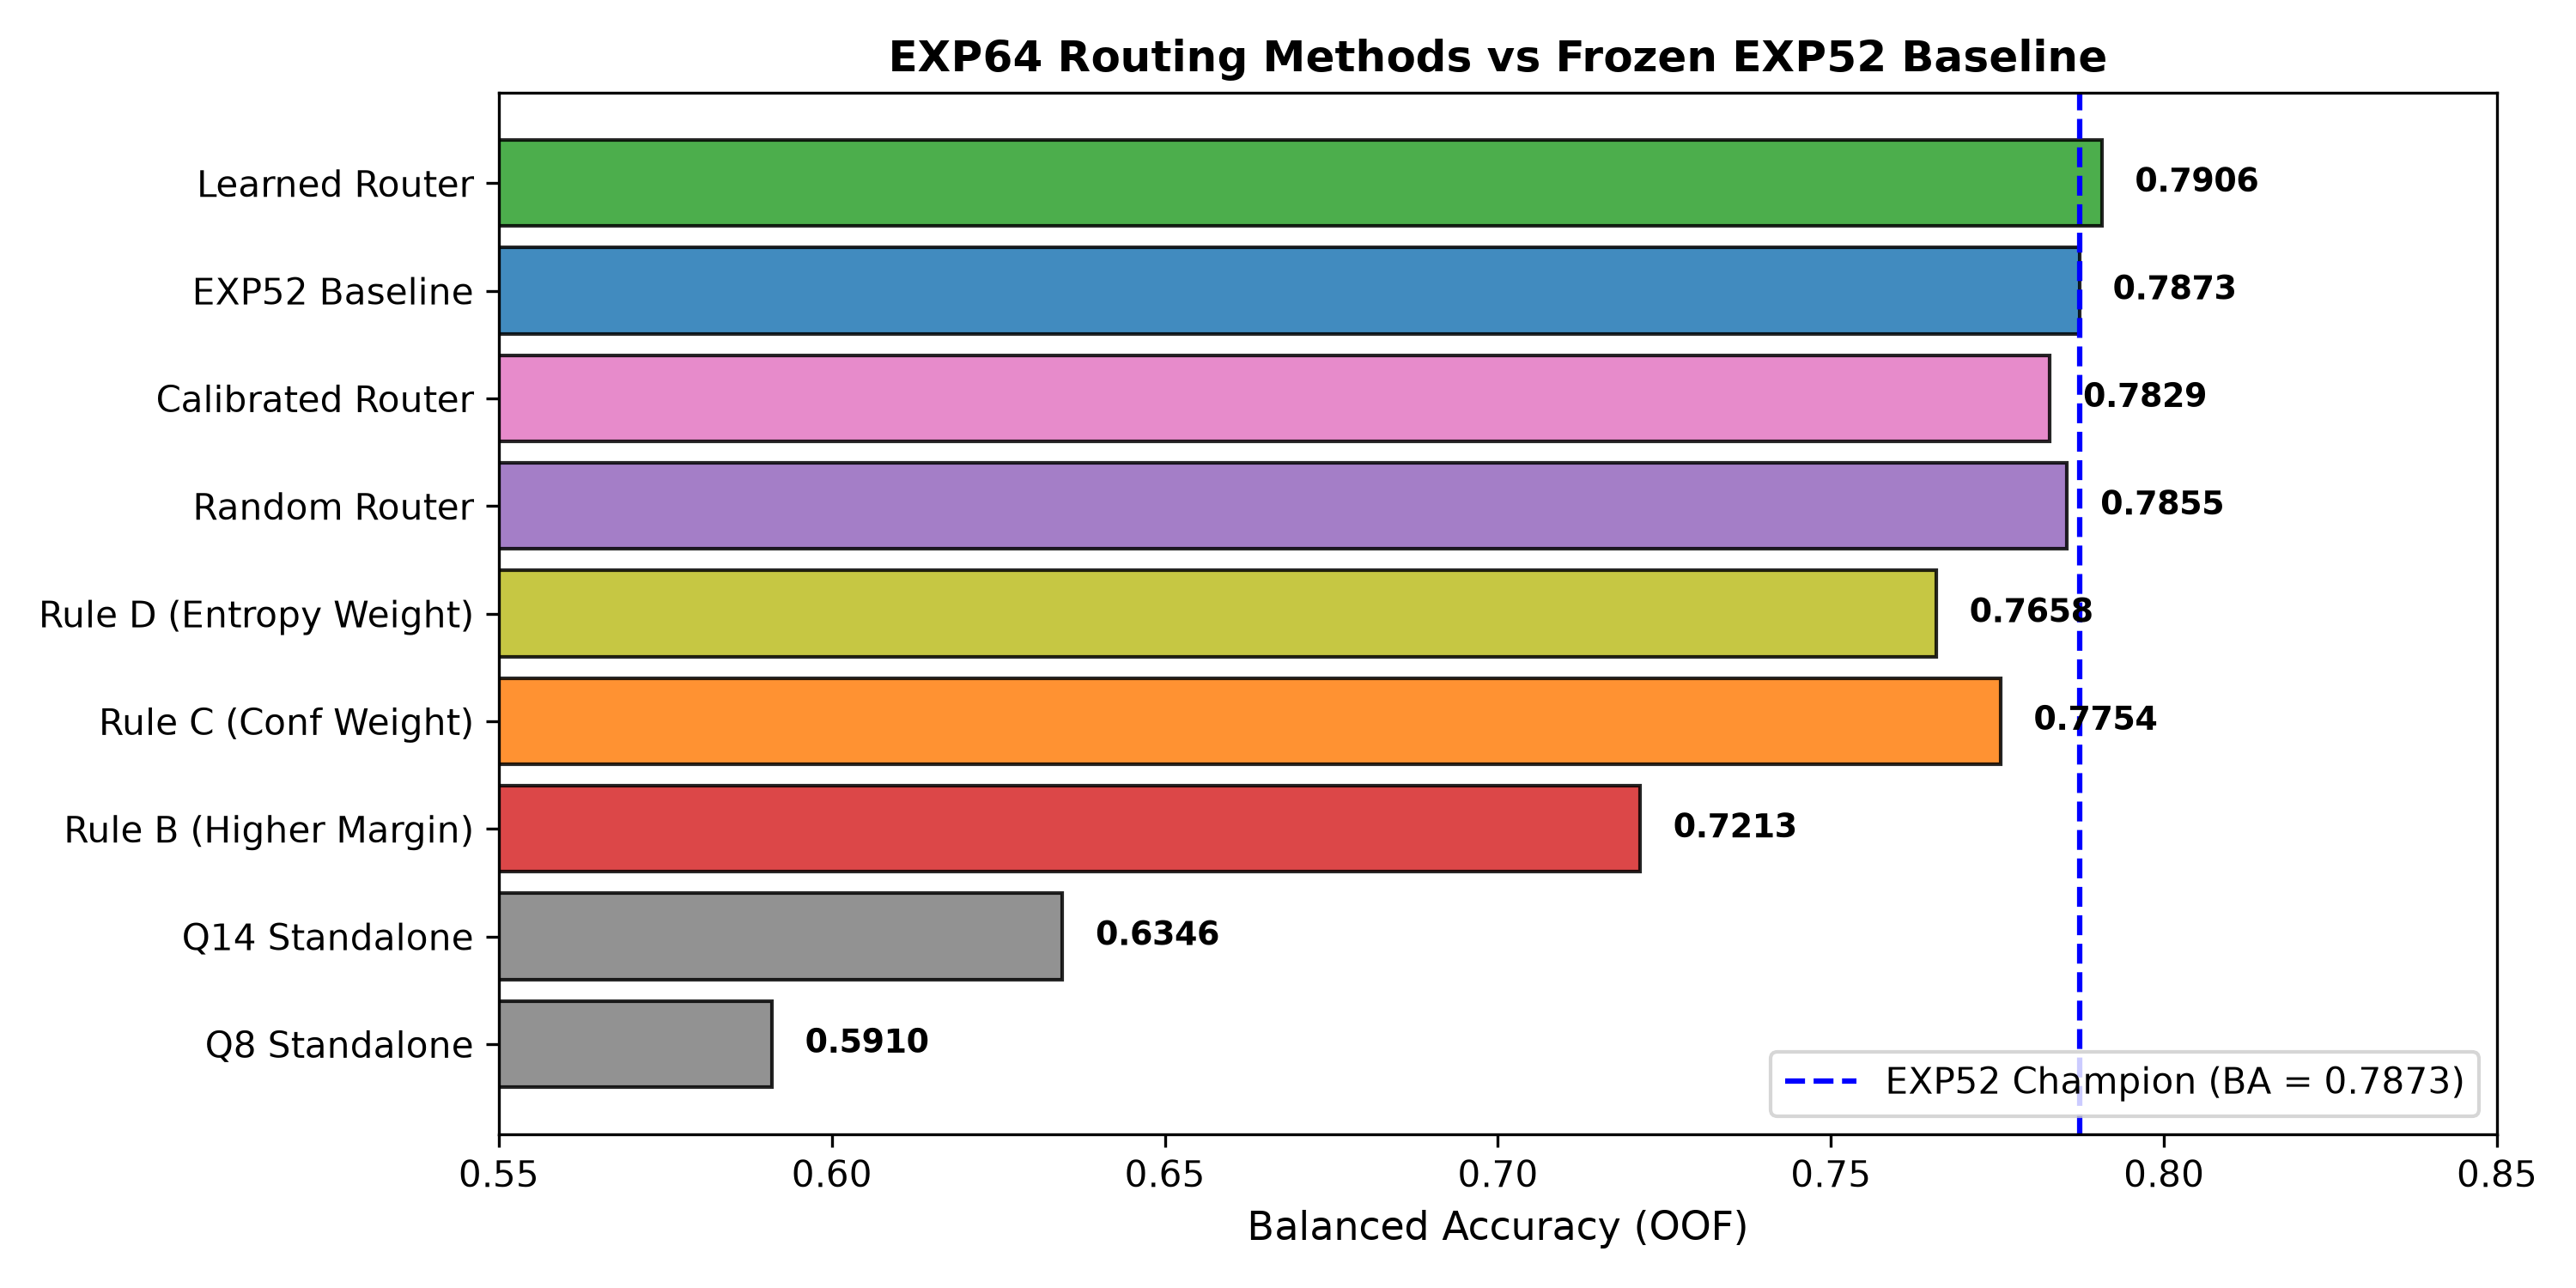

--- Figure 3: Disagreement Subset Performance ---


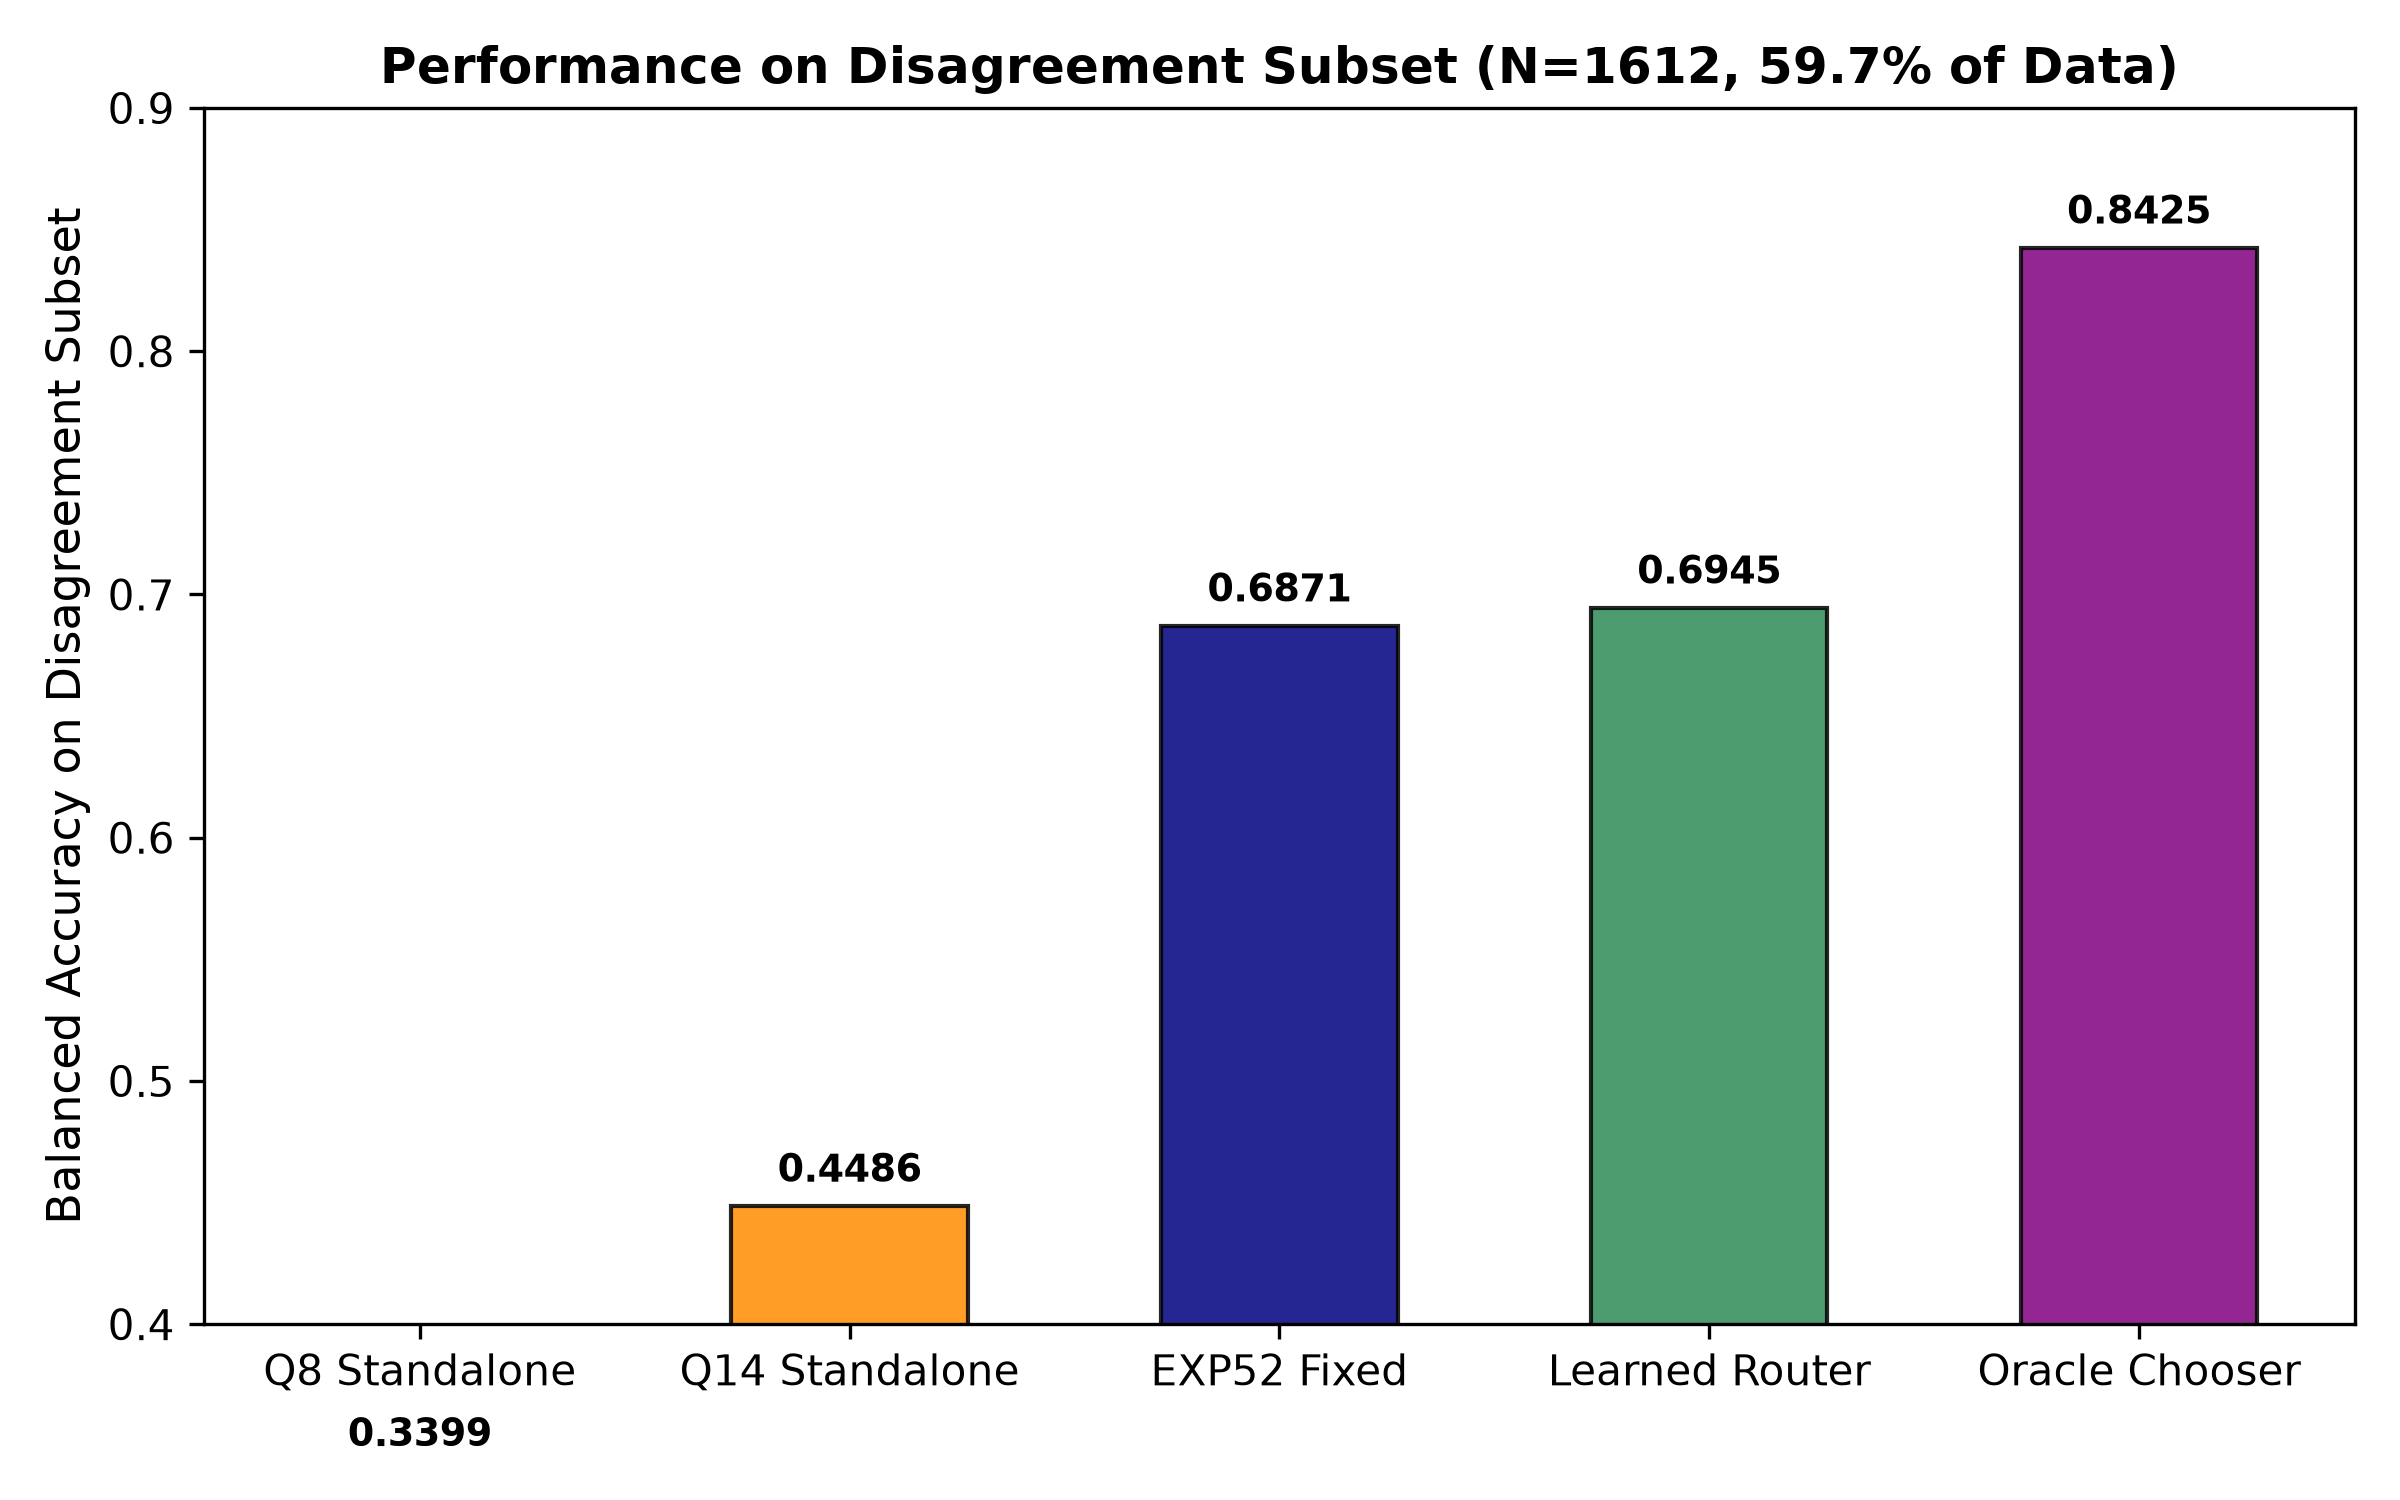

--- Figure 4: Confidence Decile Analysis ---


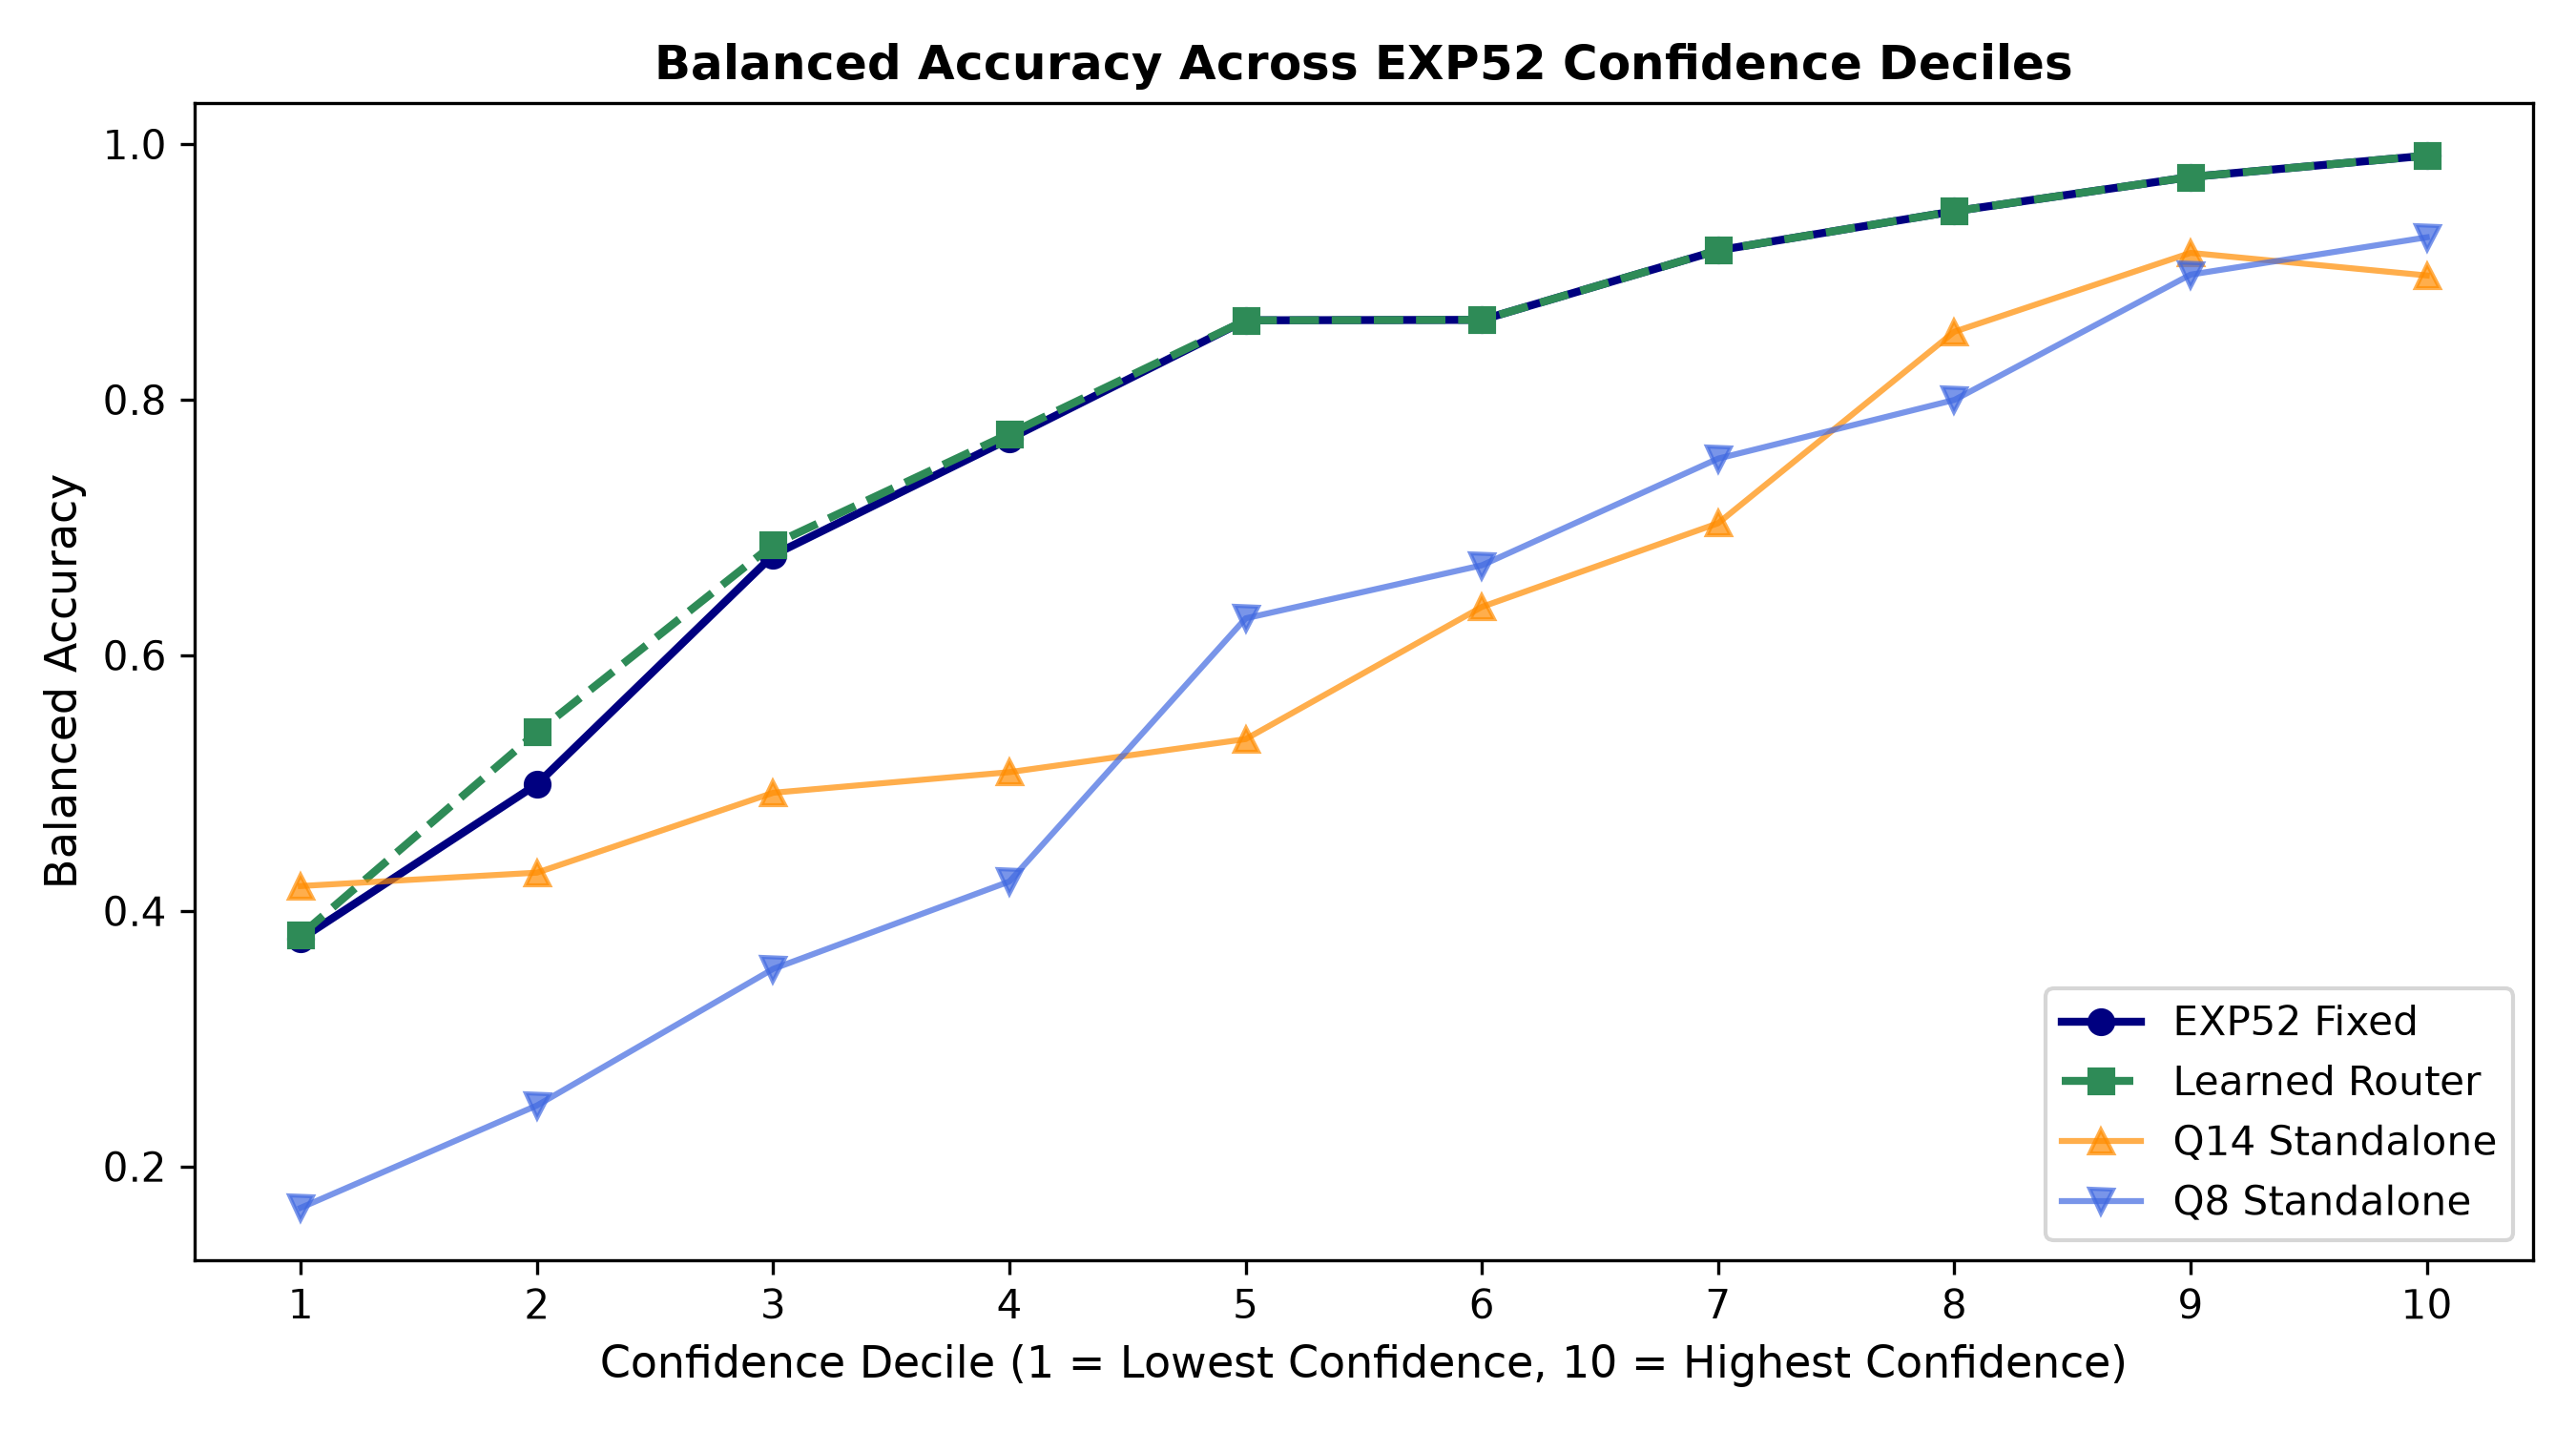

--- Figure 5: Corrections vs Degradations ---


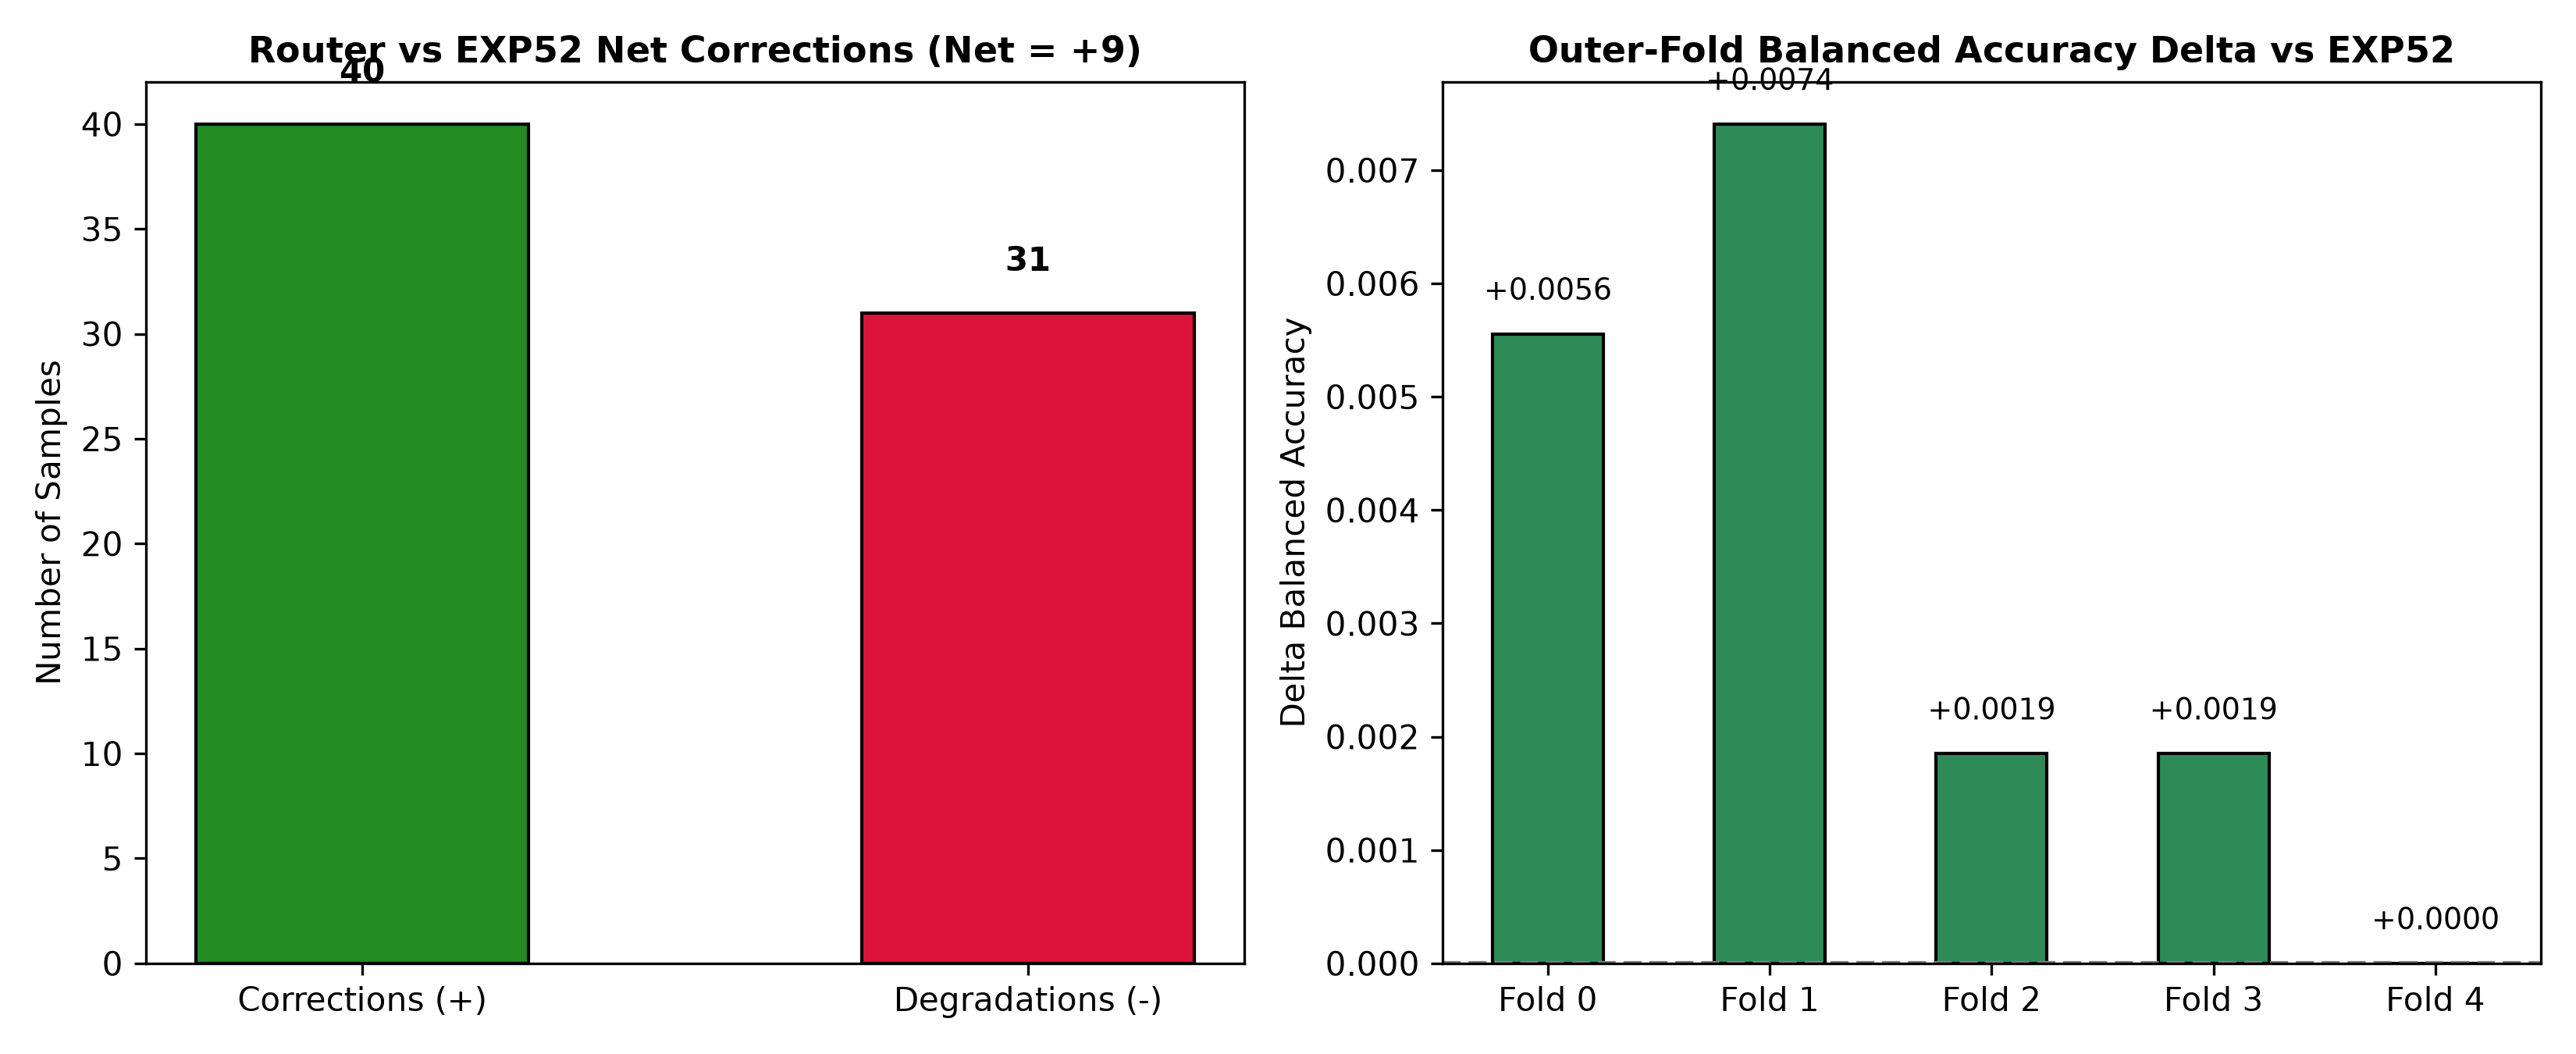

--- Figure 6: Router Feature Importance ---


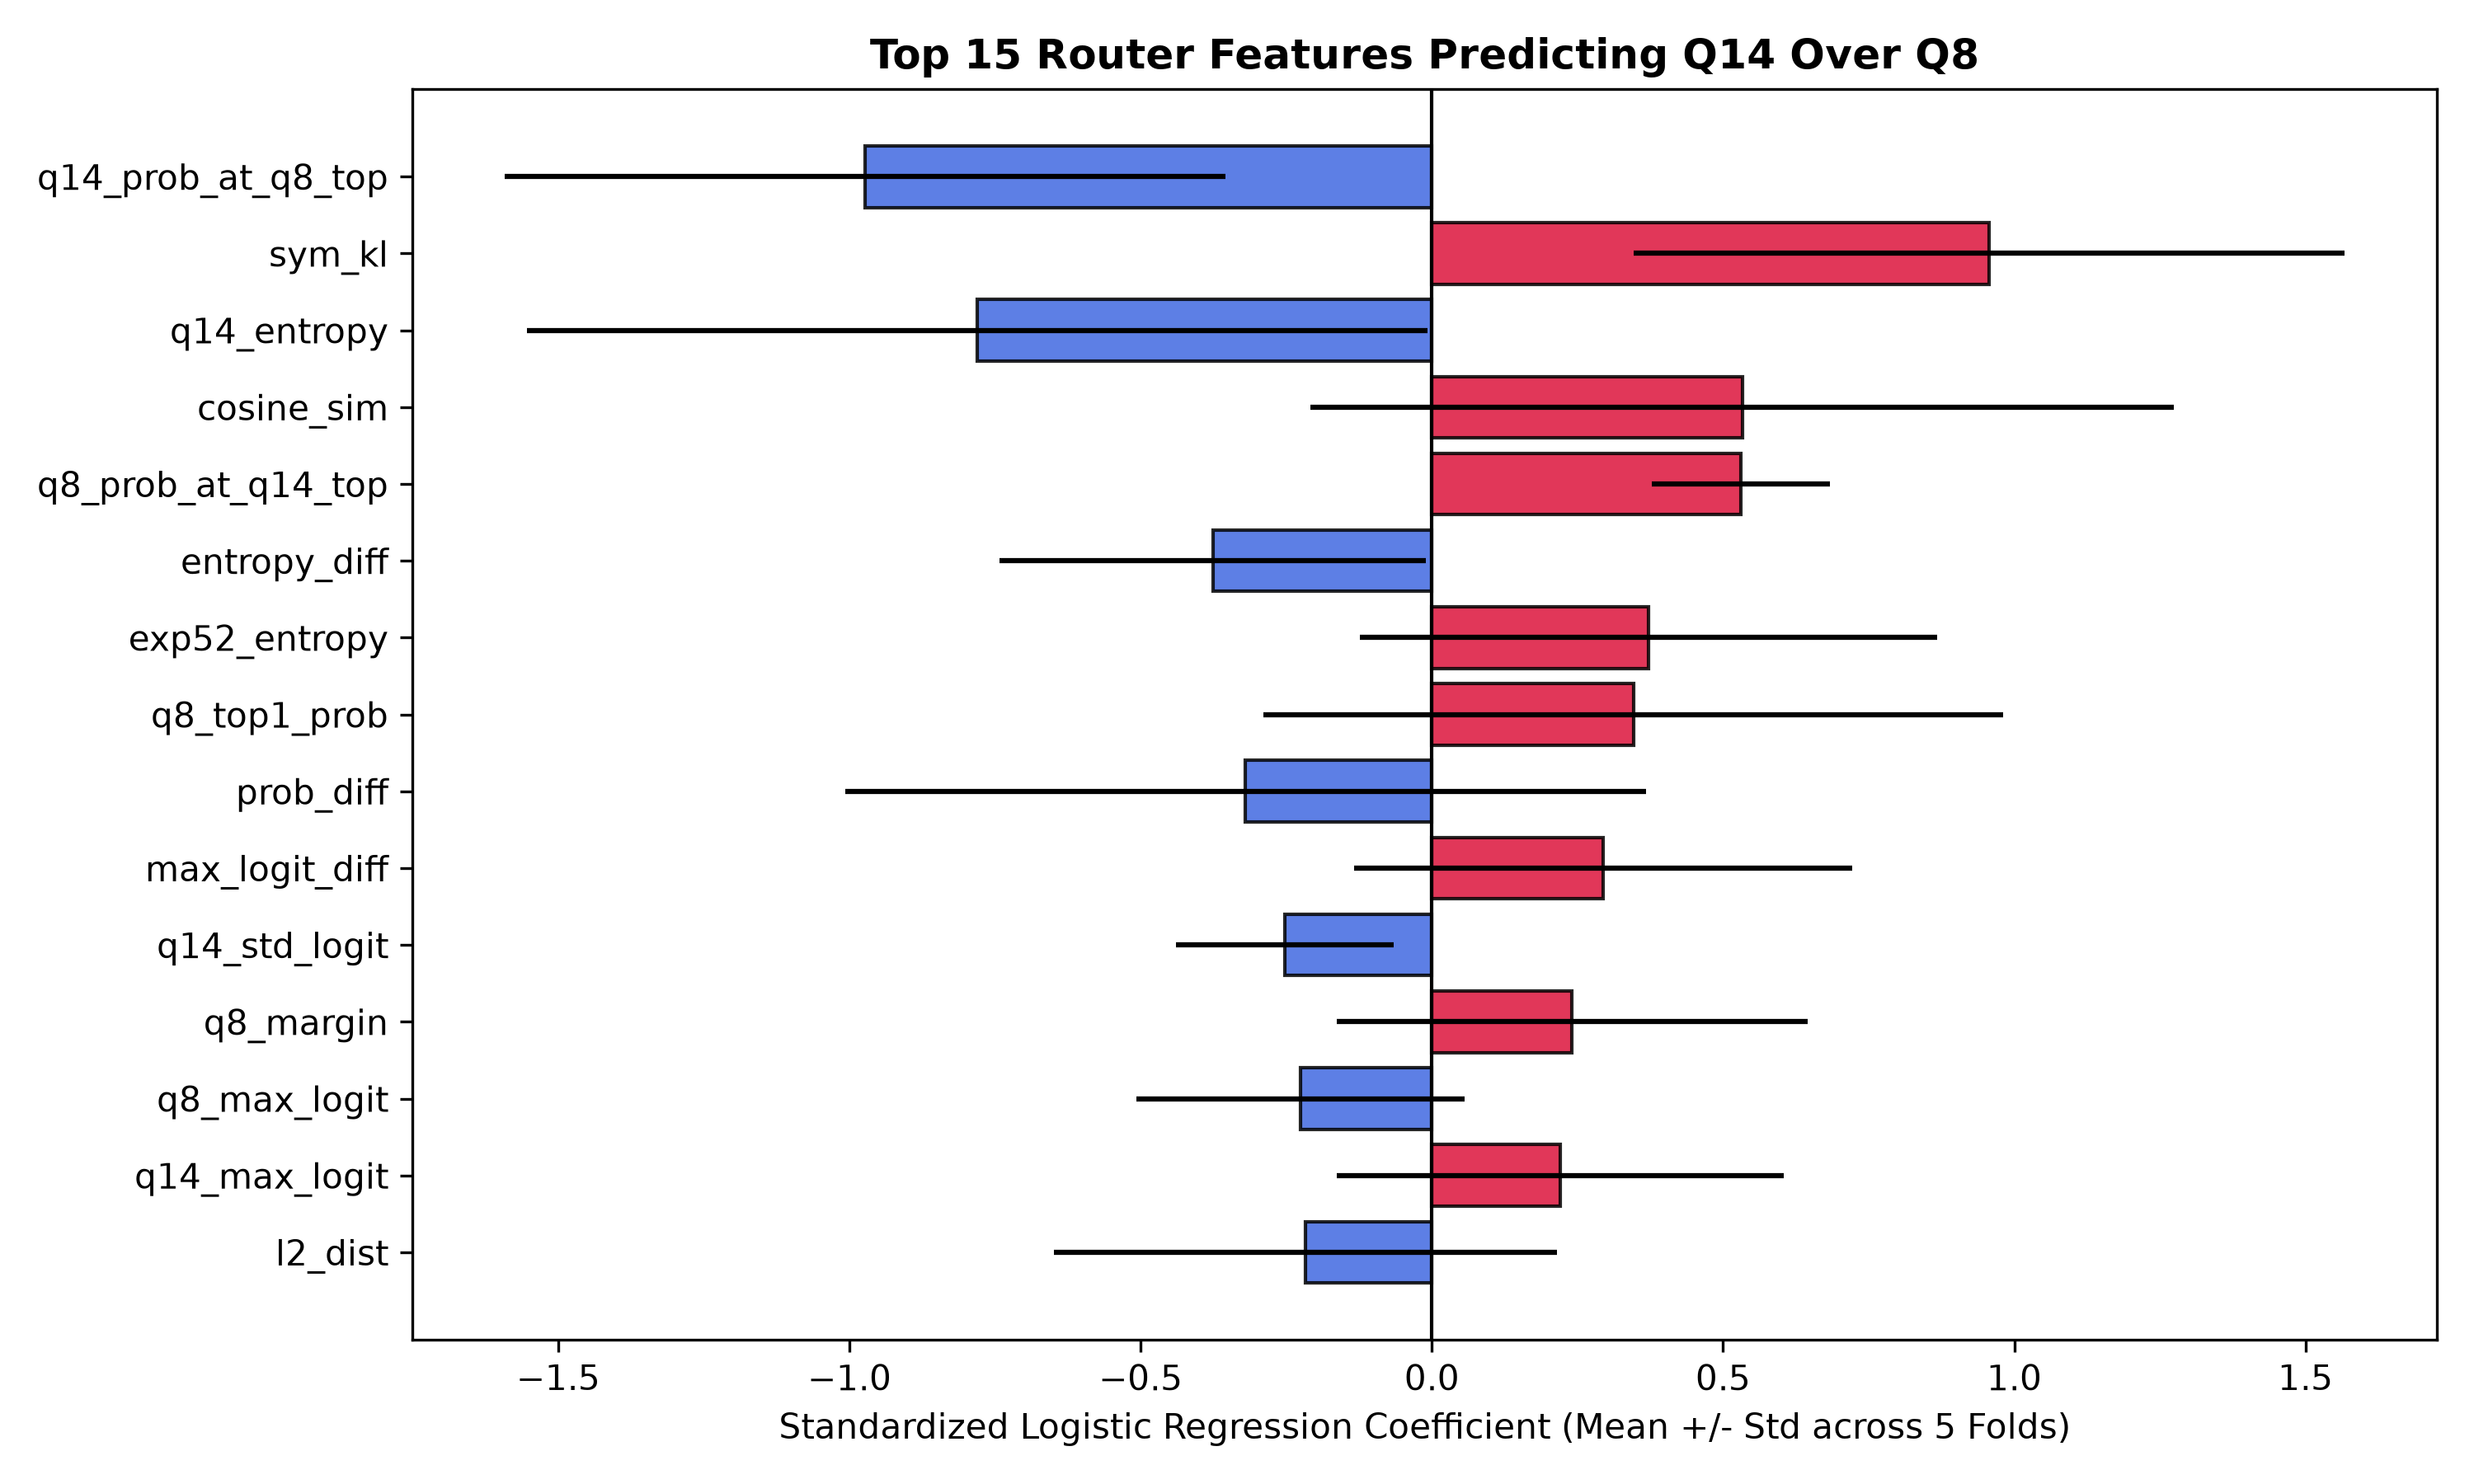

--- Figure 7: Temperature Calibration Reliability Curves ---


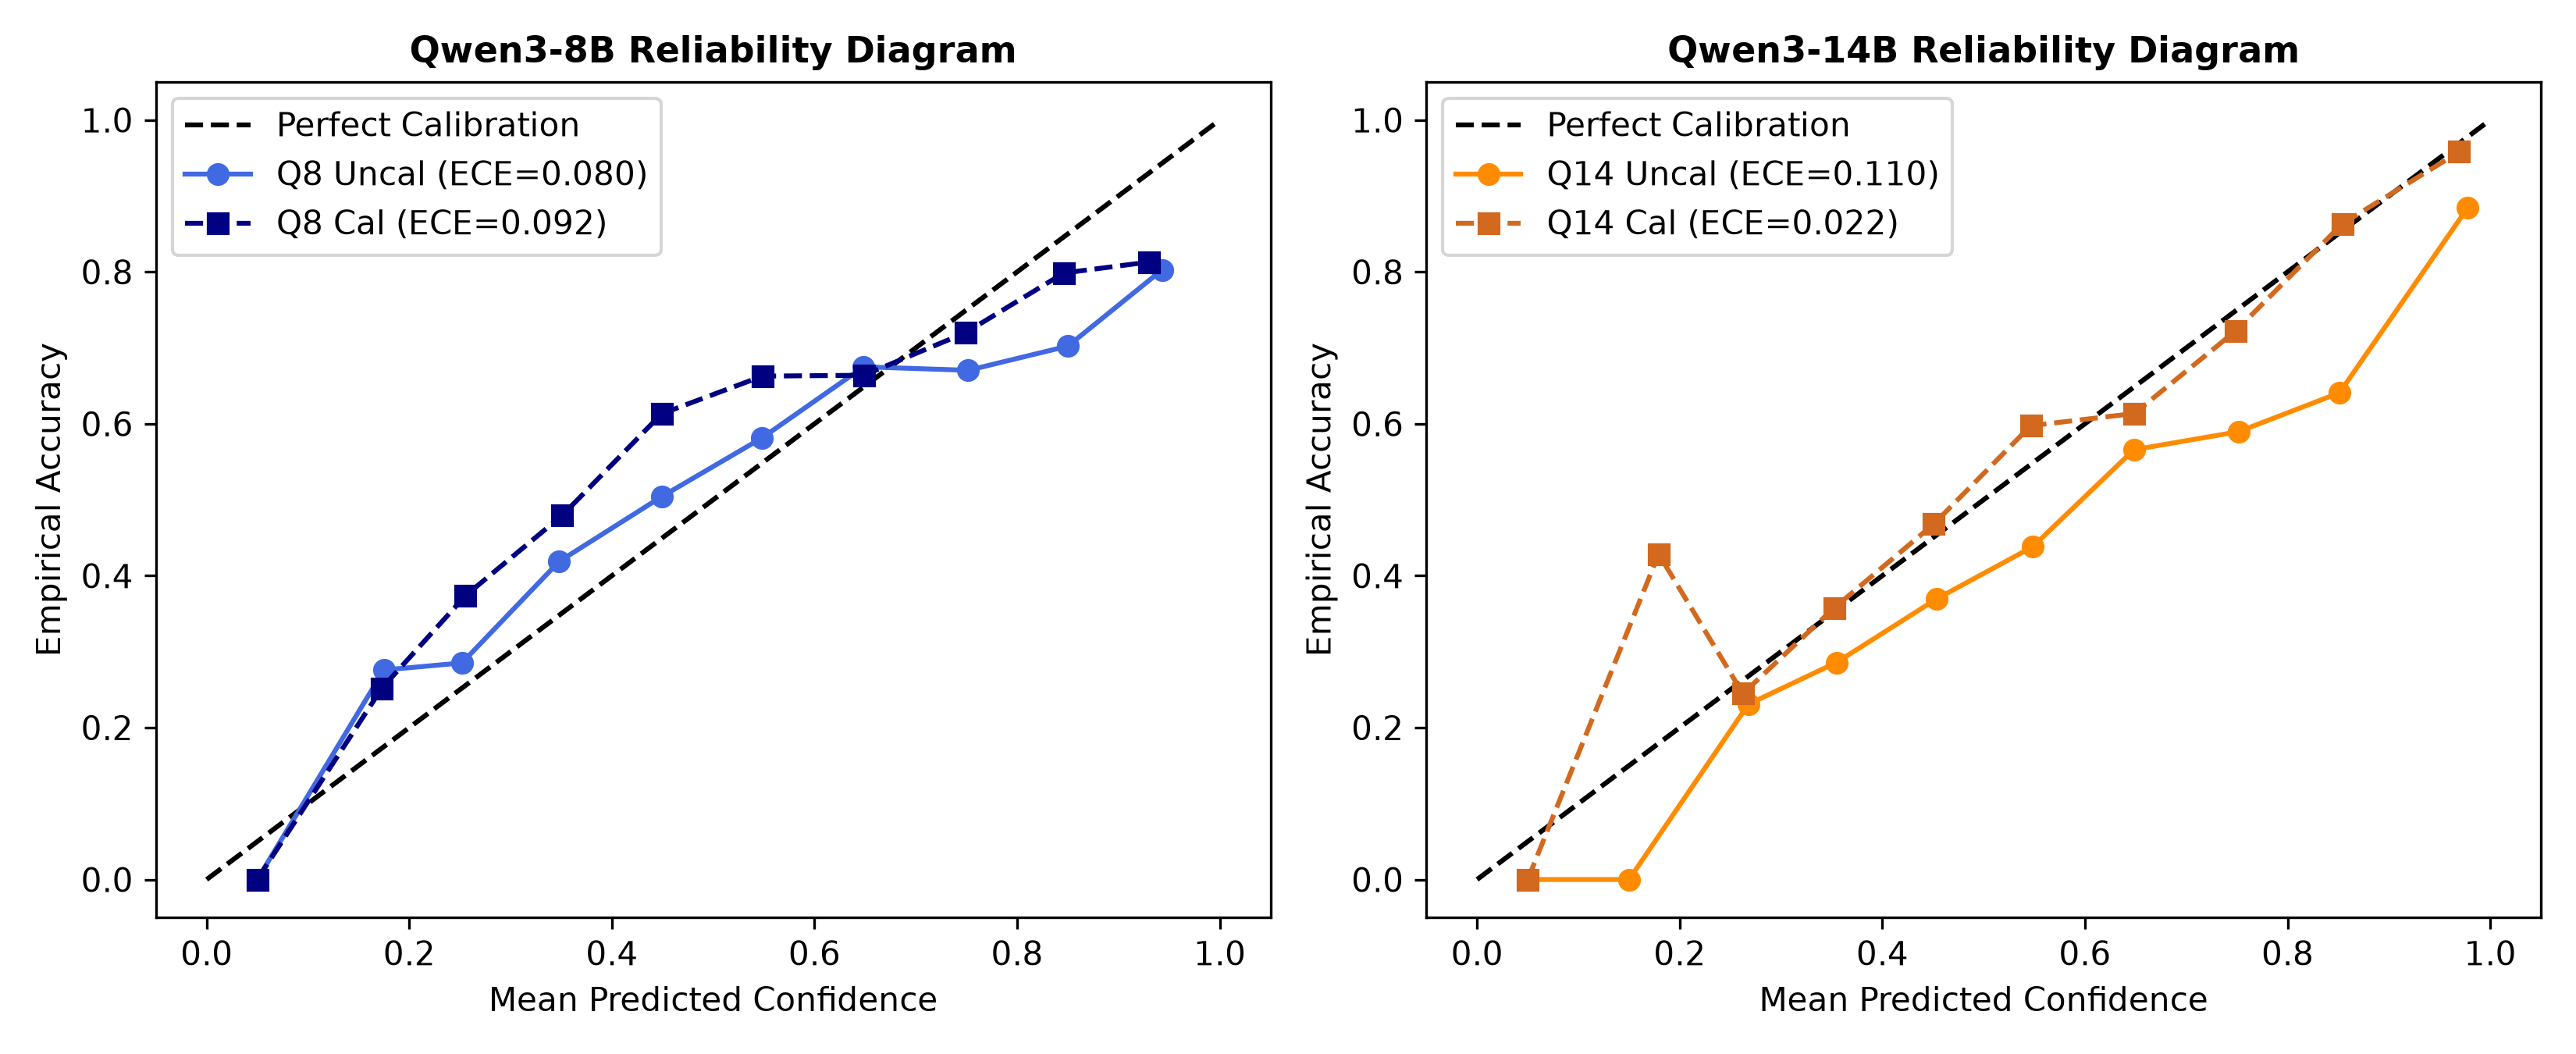

In [8]:
# 8. Render Key Figures Inline
print("--- Figure 1: Confidence Distributions by Correctness Group ---")
display(Image(filename=str(PLOTS_DIR / "exp64_confidence_distributions.png")))

print("--- Figure 2: Router Performance Comparison ---")
display(Image(filename=str(PLOTS_DIR / "exp64_router_performance.png")))

print("--- Figure 3: Disagreement Subset Performance ---")
display(Image(filename=str(PLOTS_DIR / "exp64_disagreement_analysis.png")))

print("--- Figure 4: Confidence Decile Analysis ---")
display(Image(filename=str(PLOTS_DIR / "exp64_confidence_deciles.png")))

print("--- Figure 5: Corrections vs Degradations ---")
display(Image(filename=str(PLOTS_DIR / "exp64_correction_degradation.png")))

print("--- Figure 6: Router Feature Importance ---")
display(Image(filename=str(PLOTS_DIR / "exp64_router_feature_importance.png")))

print("--- Figure 7: Temperature Calibration Reliability Curves ---")
display(Image(filename=str(PLOTS_DIR / "exp64_calibration.png")))


### 9. Final Verdict & Scientific Conclusions

- **Verdict**: **YELLOW**
- **Findings**:
  1. Observable single-sample confidence and margin features strongly correlate with correctness on training data ($t = 20.7, p < 10^{-80}$).
  2. However, under strict 5-outer $\times$ 4-inner prompt-disjoint nested cross-validation, the learned router achieves only **0.7906 BA** ($\Delta = \mathbf{+0.0033}$ over EXP52 0.7873).
  3. The 95% bootstrap confidence interval $[-0.0027, +0.0094]$ comfortably spans zero ($P(\Delta > 0) = 87.0\%$).
  4. Out of 1,612 disagreement samples, the router fixes 40 mistakes that EXP52 made, but simultaneously causes 31 regressions on samples that EXP52 correctly identified, producing a net gain of only **+9 samples**.
  5. Temperature calibration successfully reduces ECE on individual models, but severely distorts relative logit scales when combined, degrading fusion accuracy from 0.7873 to 0.7736.
- **Production Champion Decision**: **Retain EXP52 as frozen champion (0.632 LB / 0.7873 OOF BA). No Kaggle submission.**
